# MRP / 01 — Volatility model and gate V

Protocol: [`MRP 001`](../../discussions/MNQ_Return_Prediction/001_claude_mrp01_preregistration.md) §4. Time-of-day profile × HAR on deseasonalized 1-minute realized variance, yearly expanding refits (fits before 2021-01-01, 2022-01-01, 2023-01-01), judged **out of sample 2021-01-01 – 2023-06-30** on MNQ.

Gate V (all three): **V1** QLIKE below constant and time-of-day, Diebold–Mariano vs time-of-day p < 0.05 · **V2** var(z) in [0.8, 1.25] every half-year · **V3** mean ACF(z²) lags 1–12 < 0.03 and < ⅓ of ACF(r²).

Writes `01/summary.json` with `primary_scale`: `z` if V passes, `raw` otherwise (used by 02 and 03).

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("MRP_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("MRP_SYNTH_DIR") or tempfile.mkdtemp(prefix="mrp_")
    os.environ["MRP_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
OUT = Path("01"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("engine", P.MRP_VERSION, "| synthetic" if SYNTHETIC else "| real data", "| train", CFG.train)

if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    P.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.test[1], CFG)


engine 0.1.0 | real data | train (datetime.date(2020, 1, 1), datetime.date(2023, 6, 30))


In [2]:
grid, fx = P.load_inputs(CFG.train[1], CFG)
pred, fits = P.walk_forward_vol(grid, CFG.train[0], CFG.refits_train, CFG.train[1], CFG)
gate = P.vol_gate(grid, pred, CFG)
print(json.dumps(gate, indent=1))

{
 "qlike_full": -13.829633960604767,
 "qlike_tod": -13.214456309853588,
 "qlike_const": -12.83812760342496,
 "dm_vs_tod": {
  "mean_diff": 0.6169870704256855,
  "t": 14.52261208175599,
  "p_one_sided": 4.356293981454281e-48,
  "days": 622
 },
 "z_var_by_half": {
  "2021H1": 0.7744472507280575,
  "2021H2": 0.6494995802231723,
  "2022H1": 1.063378191859396,
  "2022H2": 1.0492612227022966,
  "2023H1": 0.8455065629876999
 },
 "acf_z2_mean_1_12": 0.005672093625263482,
 "acf_r2_mean_1_12": 0.05554587779165851,
 "V1": true,
 "V2": false,
 "V3": true,
 "pass": false,
 "n": 168215
}


## 1. Fits: HAR coefficients and the time-of-day profile

,const,Qh,Qd,Qw,Qm
fit before,,,,,
2021-01-01,0.0815,0.6871,0.0847,0.1607,-0.0175
2022-01-01,0.0761,0.6842,0.0894,0.1609,-0.0133
2023-01-01,0.0762,0.6661,0.0948,0.1790,-0.0188


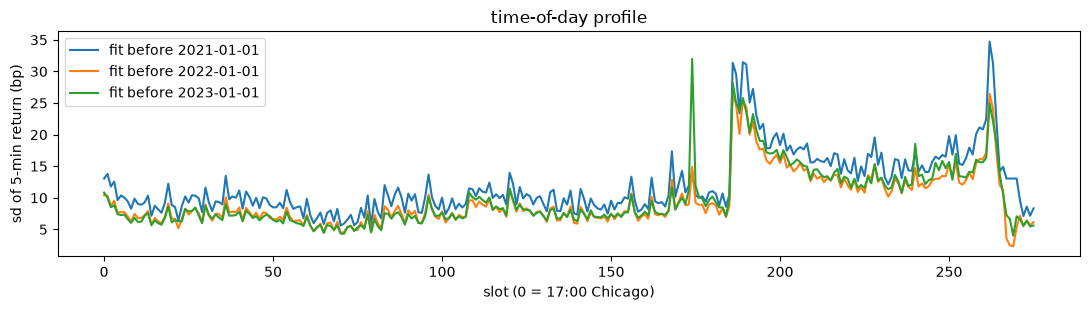

In [3]:
har = pd.DataFrame([f.beta for f in fits], columns=["const"] + [n for n, _ in CFG.har],
                   index=[str(f.fit_end) for f in fits]); har.index.name = "fit before"
display(har.round(4))
fig, ax = plt.subplots(figsize=(11, 3.2))
for f in fits:
    ax.plot(np.sqrt(f.s2_r) * 1e4, label=f"fit before {f.fit_end}")
ax.set_xlabel("slot (0 = 17:00 Chicago)"); ax.set_ylabel("sd of 5-min return (bp)"); ax.legend(); ax.set_title("time-of-day profile")
plt.tight_layout(); plt.savefig(OUT / "tod_profile.png", dpi=110); plt.show()

## 2. Loss by period, standardized returns

,full,tod,const
2021,-14.2648,-13.3181,-13.0022
2022,-13.1796,-12.8855,-12.4764
2023,-14.1538,-13.6122,-13.1750


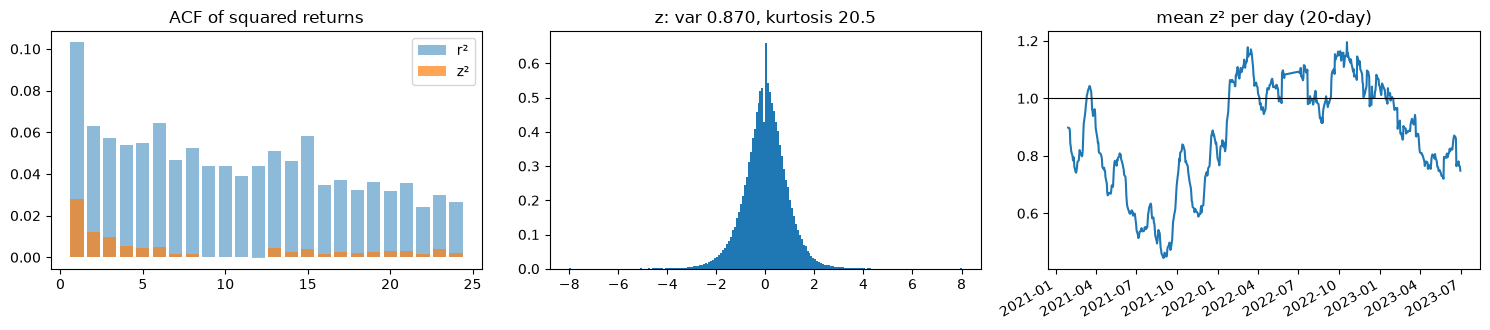

In [4]:
s = grid.loc[pred.index]
ok = (s["ret"].notna() & pred["sig2"].notna() & (s["slot"] >= CFG.drop_first) & (s["n_bars_day"] >= CFG.min_day_bars)).to_numpy()
r = s["ret"].to_numpy()[ok]; yr = pd.to_datetime(s["trade_date"].to_numpy()[ok]).year
L = pd.DataFrame({m: P.qlike(r, pred[c].to_numpy()[ok]) for m, c in (("full", "sig2"), ("tod", "sig2_tod"), ("const", "sig2_const"))})
display(L.groupby(yr).mean().round(4))
z = r / np.sqrt(pred["sig2"].to_numpy()[ok])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
lags = range(1, 25)
ac = lambda x, l: np.corrcoef(x[l:], x[:-l])[0, 1]
ax[0].bar(lags, [ac(r ** 2, l) for l in lags], alpha=.5, label="r²"); ax[0].bar(lags, [ac(z ** 2, l) for l in lags], alpha=.7, label="z²")
ax[0].legend(); ax[0].set_title("ACF of squared returns")
ax[1].hist(np.clip(z, -8, 8), bins=200, density=True); ax[1].set_title(f"z: var {z.var():.3f}, kurtosis {pd.Series(z).kurt():.1f}")
pd.Series(z ** 2, index=pd.to_datetime(s["trade_date"].to_numpy()[ok])).groupby(level=0).mean().rolling(20).mean().plot(ax=ax[2], title="mean z² per day (20-day)")
ax[2].axhline(1, color="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT / "standardized.png", dpi=110); plt.show()

## 3. Gate V

In [5]:
verdict = "PASS" if gate["pass"] else "FAIL"
primary = "z" if gate["pass"] else "raw"
print(f"Gate V: {verdict}  (V1 {gate['V1']}, V2 {gate['V2']}, V3 {gate['V3']})  -> primary scale for 02/03: {primary}")
summary = {"engine": P.MRP_VERSION, "synthetic": SYNTHETIC, "gate_V": gate, "primary_scale": primary,
           "har_coefficients": har.reset_index().to_dict("records")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=str))

Gate V: FAIL  (V1 True, V2 False, V3 True)  -> primary scale for 02/03: raw


1287